# Moving correlation: is the climate signal stable?

A tree-ring chronology is usually calibrated against climate over one period and
then used to reconstruct that climate metrics back in time. This procedure carries the implicit assumption that the growth-climate
relationship modeled during the calibration period reasonably is **stationary**. A *moving (windowed) correlation* lets you check
that assumption, at least over the instrumental period: slide a window along the chronology and a climate series, and
correlate them inside each window to get a correlation 'trace' of the relationship through time.

The trace is easy to compute and just as easy to over-interpret. `dpl.moving_corr` is intentionally built with that danger in mind. 
This notebook takes the moving correlation code through its paces on a northern
treeline dataset which has been previously investigated for the 'divergence problem' and shows, at each step, what the running correlation does and where the interpretive dangers lie. 

**Three things to keep in mind throughout:**

1. **Short overlapping windows manufacture variability in correlations (Slutsky–Yule).** Adjacent windows
   share all but one or two years, so a moving correlation of two short persistent
   series drifts up and down on its own, even when the true relationship is
   overall reasonably stable. A wandering trace is the *expected* behaviour of the null, not
   evidence against it. `moving_corr` compares the observed trace against
   red-noise surrogates that carry the same persistence and the same window, so
   the test asks only whether the trace is more variable *more than expected by chance*.
2. **You are running many tests at once (multiplicity).** A long trace reflects dozens
   of (non-independent) correlations, and adding seasons multiplies that again. Flagging every
   window that individually clears a threshold guarantees false positives, so the tests
   here are *whole-trace* and *field-level*, and *not* per-window.
3. **"Significant" vs "not significant" is not itself a finding (Gelman & Stern,
   2006).** The figures show the estimate with its uncertainty and a single
   threshold, never a grid of significance flags flickering from cell to cell.

**Data.** The chronology is ITRDB **cana326**, the "Yukon Composite" of
D'Arrigo, Wilson & Jacoby (white spruce, 1067–2002), read live from the NOAA
paleo archive. Summer temperature comes from Berkeley Earth, at the grid cell
nearest the site coordinates in the datafile.

In [24]:
import warnings
warnings.formatwarning = lambda msg, cat, *a, **k: f"{cat.__name__}: {msg}\n" # this line cleans up the warning messages that readers will print

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import dplpy as dpl

## 1. A residual chronology from the ITRDB

`dpl.readers` accepts a URL, so we can pull the measurements straight from the
NOAA archive. We detrend each series with an age-dependent spline, then build a
residual chronology which will emphasize the high frequency variability. For the residual chronology, each series is prewhitened using an AR model before averaging, with
variance stabilization used to account for changing sample depth. 

In [36]:
URL = ("https://www.ncei.noaa.gov/pub/data/paleo/treering/measurements/northamerica/canada/cana326.rwl")

rwl = dpl.readers(URL, verbose=False) # you'll still see some warnings, as the rwl file has gaps and uses -8 for unmeasured years
rwi = dpl.detrend(rwl, fit="AgeDepSpline", method="ratio", verbose=False)
chron = dpl.chron(rwi, prewhiten=True, stabilize="rbar", plot=False)
crn = chron["res_vsc"].dropna() # extract just the stabilized residual chronology from the chronology building output variable


    NRX37: 1633
    fad08b: 1605, 1615
    fad08d: 1892
    fad20a: 1699
    fdd01b: 1508, 1509
    fdd03b: 1508, 1509
    FDD05B: 1509
    fdd10b: 1540, 1574
    FDD11B: 1220
    fdd31b: 1509


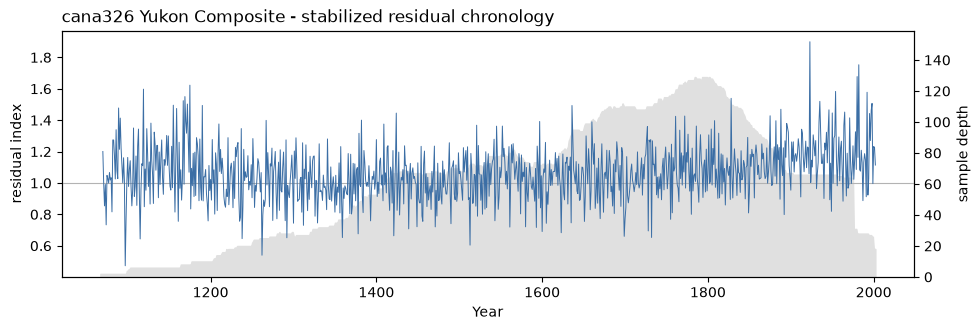

In [ ]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axhline(1, color="0.7", lw=0.8)
ax.plot(crn.index, crn.values, color="#3b6ea5", lw=0.7)
ax.set_xlabel("Year"); ax.set_ylabel("residual index")
ax.set_title("cana326 Yukon Composite - stabilized residual chronology", loc="left")
ax2 = ax.twinx()
ax2.fill_between(chron["samp_depth"].index, chron["samp_depth"].values,color="0.88", zorder=0)
ax2.set_ylabel("sample depth"); ax2.set_ylim(0, chron["samp_depth"].max()+30) # put the chronology line over the sample depth shading
ax.set_zorder(1)
plt.show()

## 2. Summer temperature

The climate series is the Berkeley Earth land+ocean grid cell nearest the site (~66.5 N, 139.5 W), supplied here as a small CSV so the notebook runs without a multi-gigabyte download. It was extracted with the following code, which adds the climatology back to the anomalies to show the annual cycle:

```python
import netCDF4, numpy as np
ds = netCDF4.Dataset("BE_Land_and_Ocean_LatLong1.nc")
lat, lon, t = ds["latitude"][:], ds["longitude"][:], ds["time"][:]
ilat = np.argmin(abs(lat - 67)); ilon = np.argmin(abs(lon - (-139)))
temp = ds["temperature"][:, ilat, ilon] + ds["climatology"][:, ilat, ilon][month-1]
```

(Correlation is unaffected by the climatology offset, so the analysis would be identical on anomalies)

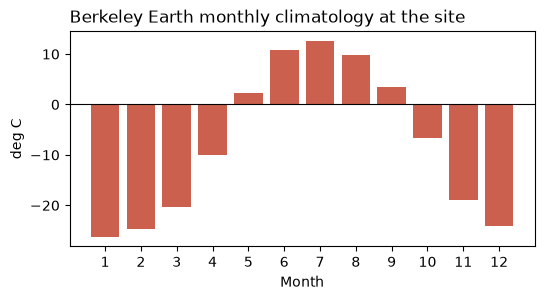

In [37]:
clim = pd.read_csv("data/cana326_berkeley_earth_67N_139W.csv")
clim = clim[["year", "month", "temp_C"]].rename(columns={"temp_C": "value"}).dropna()
mc = clim.groupby("month")["value"].mean()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(mc.index, mc.values, color="#c1442e", alpha=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("deg C")
ax.set_title("Berkeley Earth monthly climatology at the site", loc="left")
plt.show()

## 3. A first moving correlation

Correlate the chronology with a summer season — here **June–July** (`end_month=7`,
`season_length=2`) — in a 30-year window stepped one year at a time, against a
red-noise null. `plot=True` draws the standard figure.

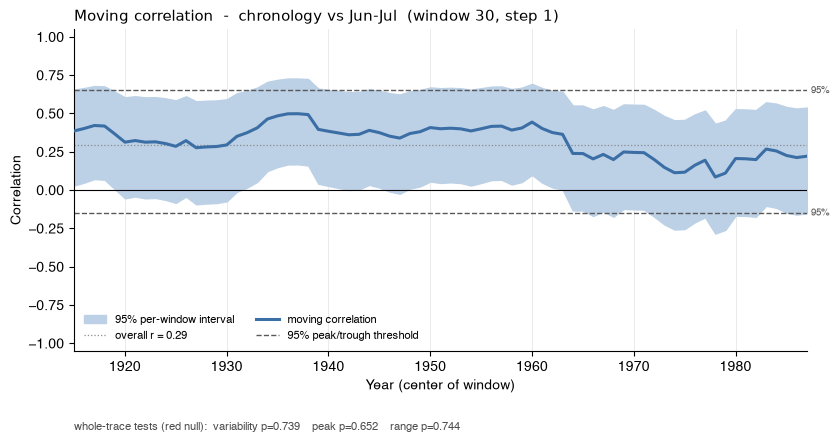

Moving correlation: chronology vs Jun-Jul
  period           : 1901-2002 (102 years)
  window / offset  : 30 / 1
  overall corr     : 0.294
  lag-1 (chron/clim): -0.141 / -0.005
  null model       : red
  std    test     : observed=0.100, p=0.739, p_lower=0.261
  range  test     : observed=0.413, p=0.744
  peak   test     : observed=0.498, p=0.652


In [38]:
res = dpl.moving_corr(crn, clim, end_month=7, season_length=2, agg="mean",
                      window=30, offset=1, noise="red",
                      period=(1901, 2002), seed=1, iters=1000, plot=True)
print(res.summary())

Three things are on that figure, and nothing else:

- **the trace** — the correlation in each window, plotted at the window centre;
- **the per-window band** — each window's own uncertainty (short windows have wide
  bands, a reminder that any single window is poorly determined);
- **one flat threshold line** from the *peak* test, which already accounts for
  having scanned the whole record.

The caption gives the **whole-trace verdicts**: `variability` (is the trace more
variable than red noise?), `peak` (is the single strongest window real?), and
`range` (is the high-to-low swing real?). There is deliberately **no grid of
per-window significance** — the difference between a window that clears the line
and one that just misses it is not itself a finding.

## 4. Be careful with window size (or, how to manufacture a signal)

Window width is a critically important parameter, because it determines the number of data points in the correlation. A short window has few degrees of freedom, so it can produce dramatic-looking structure out of almost nothing, just purely by chance. Compare an 11-year window with a 31-year window on the *same* data:

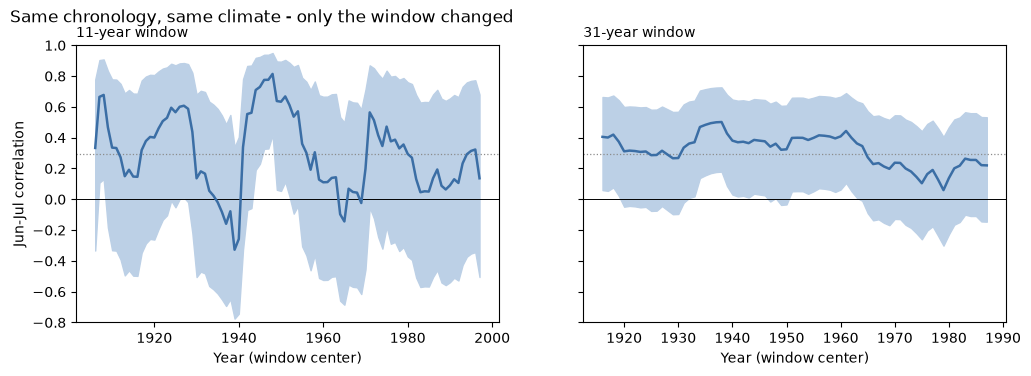

variability test p:  11-yr = 0.694    31-yr = 0.719


In [30]:
def trace_with_band(ax, window, title):
    r = dpl.moving_corr(crn, clim, end_month=7, season_length=2, agg="mean",
                        window=window, noise="red", period=(1901, 2002),
                        seed=1, iters=1000, plot=False)
    t = r.trace.index.to_numpy(float)
    ax.fill_between(t, r.trace["ci_lower"], r.trace["ci_upper"], color="#bcd0e6")
    ax.axhline(0, color="black", lw=0.7)
    ax.axhline(r.overall_corr, color="0.55", lw=0.9, ls=":")
    ax.plot(t, r.trace["r"], color="#3b6ea5", lw=1.8)
    ax.set_ylim(-0.8, 1.0); ax.set_title(title, fontsize=10, loc="left")
    return r.tests["std"].p_value

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
p11 = trace_with_band(axs[0], 11, "11-year window")
p31 = trace_with_band(axs[1], 31, "31-year window")
axs[0].set_ylabel("Jun-Jul correlation")
for ax in axs: ax.set_xlabel("Year (window center)")
fig.suptitle("Same chronology, same climate - only the window changed", x=0.07, ha="left")
plt.show()
print("variability test p:  11-yr = %.3f    31-yr = %.3f" % (p11, p31))

The 11-year correlation trace swings from strongly positive to near zero and back,
looking for all the world like a relationship that switches on and off. But the
per-window uncertainty bands are enormous, and the **variability tests do not flag this a greater than expected by change**: that
much wandering is exactly what red noise produces on an 11-year window for weakly correlated series. The
31-year trace is steadier and its bands are tighter. Short windows don't reveal
hidden instability in this case, but rather they manufacture it. The significance test allows us to see this. 

The comparion parameter to the window width is `offset` (the step between windows): `offset=1` gives a
smooth, fully-overlapping trace, `offset=window` gives adjacent, independent
windows, and anything between trades smoothness for independence. The null is
always computed at the same window and offset, so the test stays fair whichever
you choose.

## 5. The whole season grid

Rather than pick one season by hand, pass `season_lengths` (plural) to scan the
entire seascorr-style grid — every season length across every ending month — in
one call. This returns a grid result with three views and **field significance**
across the grid.

In [31]:
grid = dpl.moving_corr(crn, clim, end_month=12, season_lengths=(1, 2, 3),
                       agg="mean", window=30, offset=1, noise="red",
                       period=(1901, 2002), seed=1, iters=500, lc_iters=300)
print(grid.summary())

Moving correlation grid (moving seascorr)
  period        : 1901-2002 (102 years)
  seasons       : 42 cells, lengths (1, 2, 3)
  window/offset : 30 / 1
  null model    : red
  FDR           : 0 of 42 seasons significant (crit p=0.0000)
  Livezey-Chen  : 0 locally-significant cells vs ~2 expected, field p=1.000


### The surface

A season-by-time heatmap of the moving correlation (red positive, white near
zero). You can read, at a glance, which seasons carry the signal and how it
changes through time — without any per-cell significance mask.

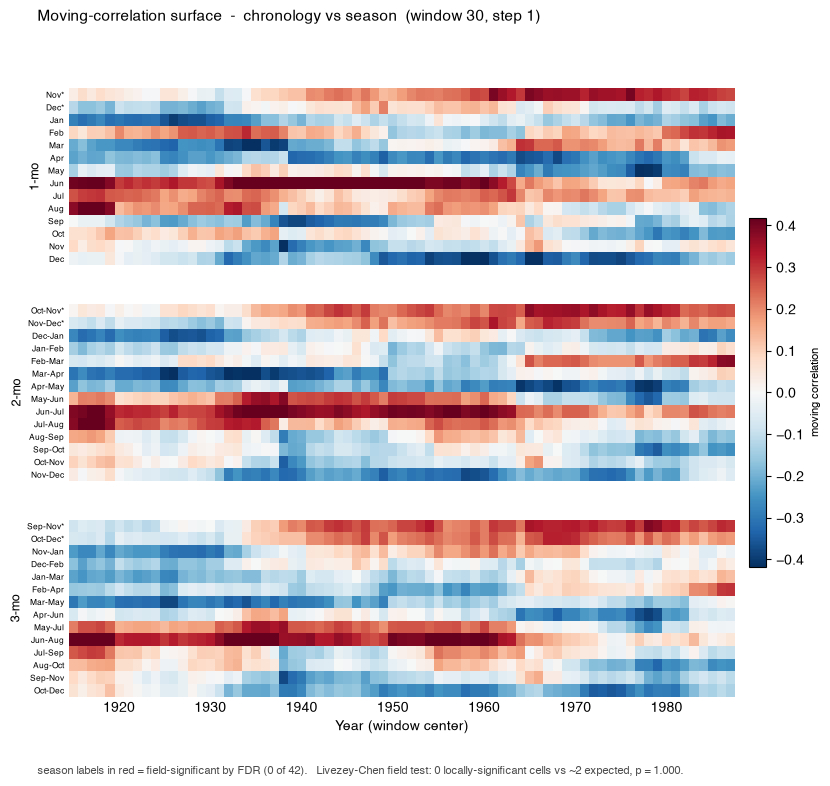

In [32]:
grid.plot(kind="surface");

### Plotting small multiples

For a chosen handful of seasons, the single-season trace-with-band tiled together
— the most faithful view, with `*` marking any season that survives multiplicity
(FDR).

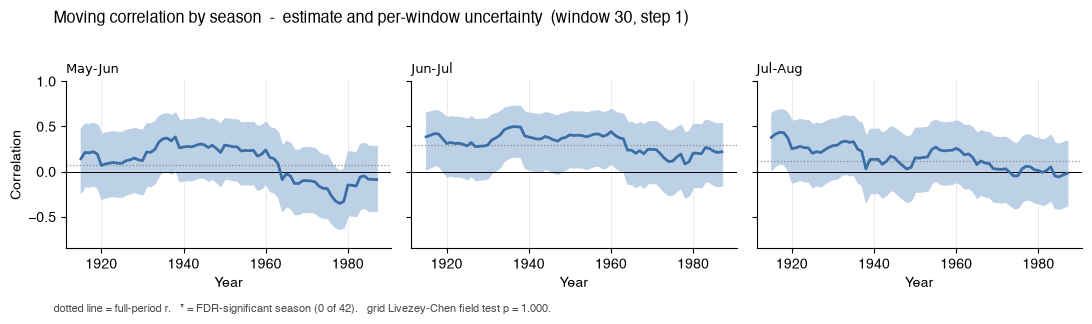

In [34]:
grid.plot(kind="small_multiples", seasons=[(2, 6), (2, 7), (2, 8)]); # numbers indicate (season length, end month of season)

### Which season carries the signal, over time

The dominant-season view collapses one season length to its argmax: the ending
month with the strongest correlation in each window, colored by the strength of the relationship, with a
grey bar spanning the seasons within 90% of the best correlation (short = stable signals, wide = ambiguous signal).

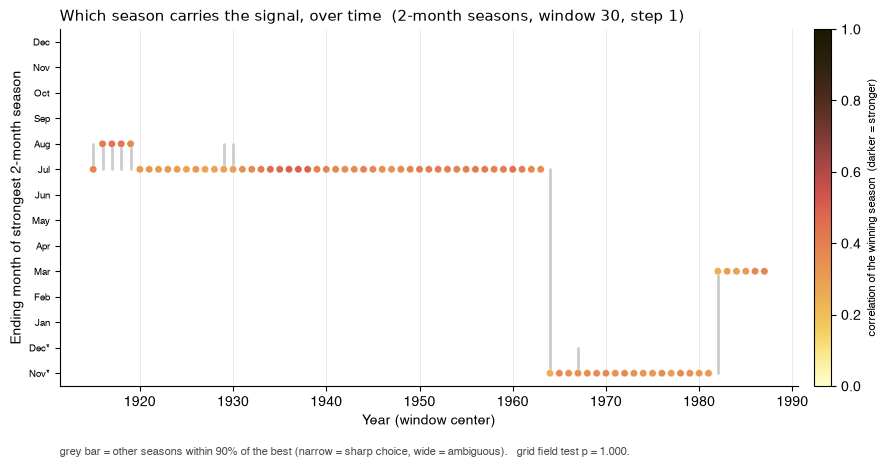

In [17]:
grid.plot(kind="dominant", season_length=2);

### Field significance

Scanning dozens of seasons across many windows is a severe multiple-comparisons
problem, made worse because neighboring seasons share months. `moving_corr`
reports two things for two questions. The **Livezey–Chen** test is the grid-level
headline — is this chronology's seasonal signal, *as a whole*, more non-stationary
than a chronology unrelated to climate? The **Benjamini–Hochberg FDR** set is the
per-season annotation (the `*` marks and the red surface labels). Both appear in
`grid.summary()` above and on the figures.

## 6. When a moving correlation is the wrong tool

The variability/peak/range tests are built to reject the artefacts of overlapping
windows, but this can make them insensitive to a smooth, monotonic decline in correlation. A steadily weakening relationship wanders much like red noise does. If what you
care about is progressive divergence — a signal that fades between an early and a late period
— a moving correlation can may not trigger the significance tests. For that question, you can test the two periods directly (e.g. an epochal
split with a Fisher-z difference, as in the stability test of [`dpl.seascorr`](../guide/seascorr.md)) rather than asking whether the running
trace is more variable than noise would suggest.

The moving correlation is a tool, but you have to be careful when interpreting its results.  It can be useful for seeing
*where and when* a signal lives and for avoiding being fooled by short-window
structure, but pairing this tool with the right statistical test for the question you are actually
asking is vital

## References

- Zang, C., Biondi, F. (2014). treeclim: an R package for the numerical
  calibration of proxy-climate relationships. *Ecography* 38(4), 431-436.
- Gershunov, A., Schneider, N., Barnett, T. (2001). Low-frequency modulation of
  the ENSO-Indian monsoon rainfall relationship: signal or noise? *J. Climate*
  14, 2486-2492.
- Gelman, A., Stern, H. (2006). The difference between "significant" and "not
  significant" is not itself statistically significant. *The American
  Statistician* 60(4), 328-331.
- Livezey, R.E., Chen, W.Y. (1983). Statistical field significance and its
  determination by Monte Carlo techniques. *Monthly Weather Review* 111, 46-59.
- D'Arrigo, R., Wilson, R., Jacoby, G. (2006). On the long-term context for late
  twentieth century warming. *J. Geophys. Res.* 111, D03103. *(cana326)*
- Rohde, R.A., Hausfather, Z. (2020). The Berkeley Earth land/ocean temperature
  record. *Earth Syst. Sci. Data* 12, 3469-3479.

See the [Moving correlation guide](../guide/moving-correlation.md) for more on the
method and its interpretation.